# Notebook 4: Autoregressive Generation

## How Token Probabilities Chain Into Full Text

LLMs generate text **one token at a time**. Each new token is appended to the input, and the model runs again on the extended sequence. This is **autoregressive generation**.

$$P(\text{sequence}) = P(t_1) \cdot P(t_2|t_1) \cdot P(t_3|t_1, t_2) \cdots$$

Each token's probability is **conditioned on all previous tokens**. We'll watch this process unfold step by step.

In [1]:
import torch
import torch.nn.functional as F
from transformers import GPT2LMHeadModel, GPT2Tokenizer
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")

tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2")
model.eval()

/Users/nijjohnson/Projects/token-probabilities/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 20987.12it/s]


GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

## Step-by-Step Generation with Full Probability Tracking

Let's generate text one token at a time and record the probability of each chosen token, the alternatives the model considered, and the running sequence probability.

In [2]:
def generate_with_trace(prompt, max_tokens=15, temperature=1.0, top_p=0.9):
    """Generate tokens one at a time, recording full trace data."""
    input_ids = tokenizer.encode(prompt, return_tensors="pt")
    generated = input_ids[0].tolist()
    
    trace = []  # Store info about each generation step
    
    for step in range(max_tokens):
        with torch.no_grad():
            logits = model(torch.tensor([generated])).logits[0, -1, :]
        
        # Apply temperature
        scaled_logits = logits / temperature
        
        # Apply top-p
        sorted_logits, sorted_indices = torch.sort(scaled_logits, descending=True)
        sorted_probs = F.softmax(sorted_logits, dim=0)
        cumsum = torch.cumsum(sorted_probs, dim=0)
        cutoff = (cumsum - sorted_probs) >= top_p
        sorted_logits[cutoff] = float("-inf")
        
        # Get final probabilities
        final_probs = F.softmax(scaled_logits, dim=0)
        all_probs = F.softmax(logits, dim=0)  # Unfiltered for recording
        
        # Sample
        filtered_probs = F.softmax(sorted_logits, dim=0)
        sample_pos = torch.multinomial(filtered_probs, 1)
        chosen_id = sorted_indices[sample_pos].item()
        
        # Record top 5 alternatives
        top5_probs, top5_indices = torch.topk(all_probs, 5)
        alternatives = [(tokenizer.decode([idx]), p.item()) 
                       for idx, p in zip(top5_indices, top5_probs)]
        
        trace.append({
            "step": step,
            "chosen_token": tokenizer.decode([chosen_id]),
            "chosen_id": chosen_id,
            "chosen_prob": all_probs[chosen_id].item(),
            "chosen_logprob": torch.log(all_probs[chosen_id]).item(),
            "alternatives": alternatives,
            "entropy": -(all_probs * torch.log(all_probs + 1e-10)).sum().item(),
        })
        
        generated.append(chosen_id)
    
    return generated, trace

# Generate with tracing
prompt = "The secret to happiness is"
torch.manual_seed(42)
generated_ids, trace = generate_with_trace(prompt, max_tokens=15, temperature=0.8, top_p=0.9)

full_text = tokenizer.decode(generated_ids)
print(f'Prompt:    "{prompt}"')
print(f'Generated: "{full_text}"\n')

# Show step-by-step trace
print(f"{'Step':>4s}  {'Chosen':>12s}  {'Prob':>8s}  {'LogProb':>8s}  {'Entropy':>8s}  Top Alternatives")
print("-" * 90)

running_logprob = 0.0
for t in trace:
    running_logprob += t["chosen_logprob"]
    alts = " | ".join([f"{tok.strip()}: {p:.1%}" for tok, p in t["alternatives"][:3]])
    print(f"{t['step']:4d}  {t['chosen_token']:>12s}  {t['chosen_prob']:8.1%}  "
          f"{t['chosen_logprob']:8.3f}  {t['entropy']:8.3f}  {alts}")

print(f"\nSequence log-probability: {running_logprob:.3f}")
print(f"Sequence probability: {np.exp(running_logprob):.2e}")

Prompt:    "The secret to happiness is"
Generated: "The secret to happiness is to get it right. If you don't know what you're doing,"

Step        Chosen      Prob   LogProb   Entropy  Top Alternatives
------------------------------------------------------------------------------------------
   0            to     18.7%    -1.677     4.975  to: 18.7% | not: 12.2% | that: 5.4%
   1           get      2.0%    -3.904     4.958  be: 13.3% | have: 5.5% | live: 4.7%
   2            it     12.5%    -2.080     4.590  it: 12.5% | out: 7.1% | rid: 6.1%
   3         right     15.1%    -1.890     4.025  right: 15.1% | out: 10.6% | done: 7.8%
   4             .     45.3%    -0.793     2.658  .: 45.3% | ,: 12.7% | and: 7.5%
   5            If      3.3%    -3.403     4.449  : 25.4% | It: 4.8% | And: 4.6%
   6           you     61.2%    -0.490     2.145  you: 61.2% | we: 6.6% | it: 5.9%
   7           don     14.4%    -1.935     3.885  don: 14.4% | 're: 13.7% | can: 12.3%
   8            't    100.0% 

## Visualizing the Generation Process

Let's visualize how token probability and model uncertainty (entropy) evolve during generation.

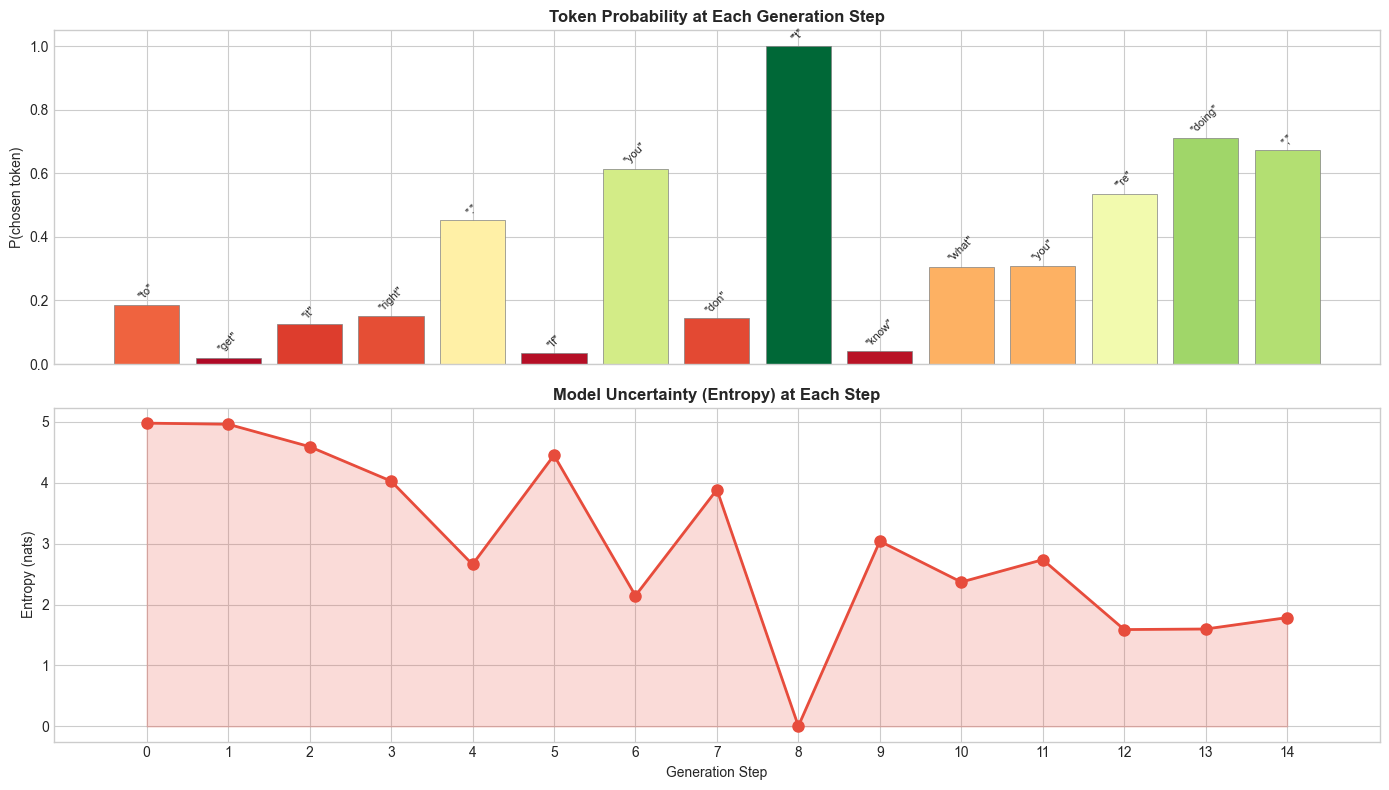

Higher entropy = model is more uncertain about the next token
Lower entropy = model is confident (probability concentrated on few tokens)


In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

steps = [t["step"] for t in trace]
chosen_probs = [t["chosen_prob"] for t in trace]
entropies = [t["entropy"] for t in trace]
tokens = [t["chosen_token"].strip() for t in trace]

# Token probability at each step
colors = plt.cm.RdYlGn([p / max(chosen_probs) for p in chosen_probs])
bars1 = ax1.bar(steps, chosen_probs, color=colors, edgecolor="gray", linewidth=0.5)
ax1.set_ylabel("P(chosen token)")
ax1.set_title("Token Probability at Each Generation Step", fontweight="bold")

# Add token labels on bars
for bar, token, prob in zip(bars1, tokens, chosen_probs):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f'"{ token}"', ha="center", va="bottom", fontsize=8, rotation=45)

# Entropy at each step (model uncertainty)
ax2.plot(steps, entropies, "o-", color="#e74c3c", linewidth=2, markersize=8)
ax2.fill_between(steps, entropies, alpha=0.2, color="#e74c3c")
ax2.set_ylabel("Entropy (nats)")
ax2.set_xlabel("Generation Step")
ax2.set_title("Model Uncertainty (Entropy) at Each Step", fontweight="bold")
ax2.set_xticks(steps)

plt.tight_layout()
plt.show()

print("Higher entropy = model is more uncertain about the next token")
print("Lower entropy = model is confident (probability concentrated on few tokens)")

## The Branching Tree of Possibilities

At every step, the model could have gone a different direction. Let's visualize the "branching tree" of the top alternatives at each step to show how generation is a path through a vast tree of possibilities.

StopIteration: 

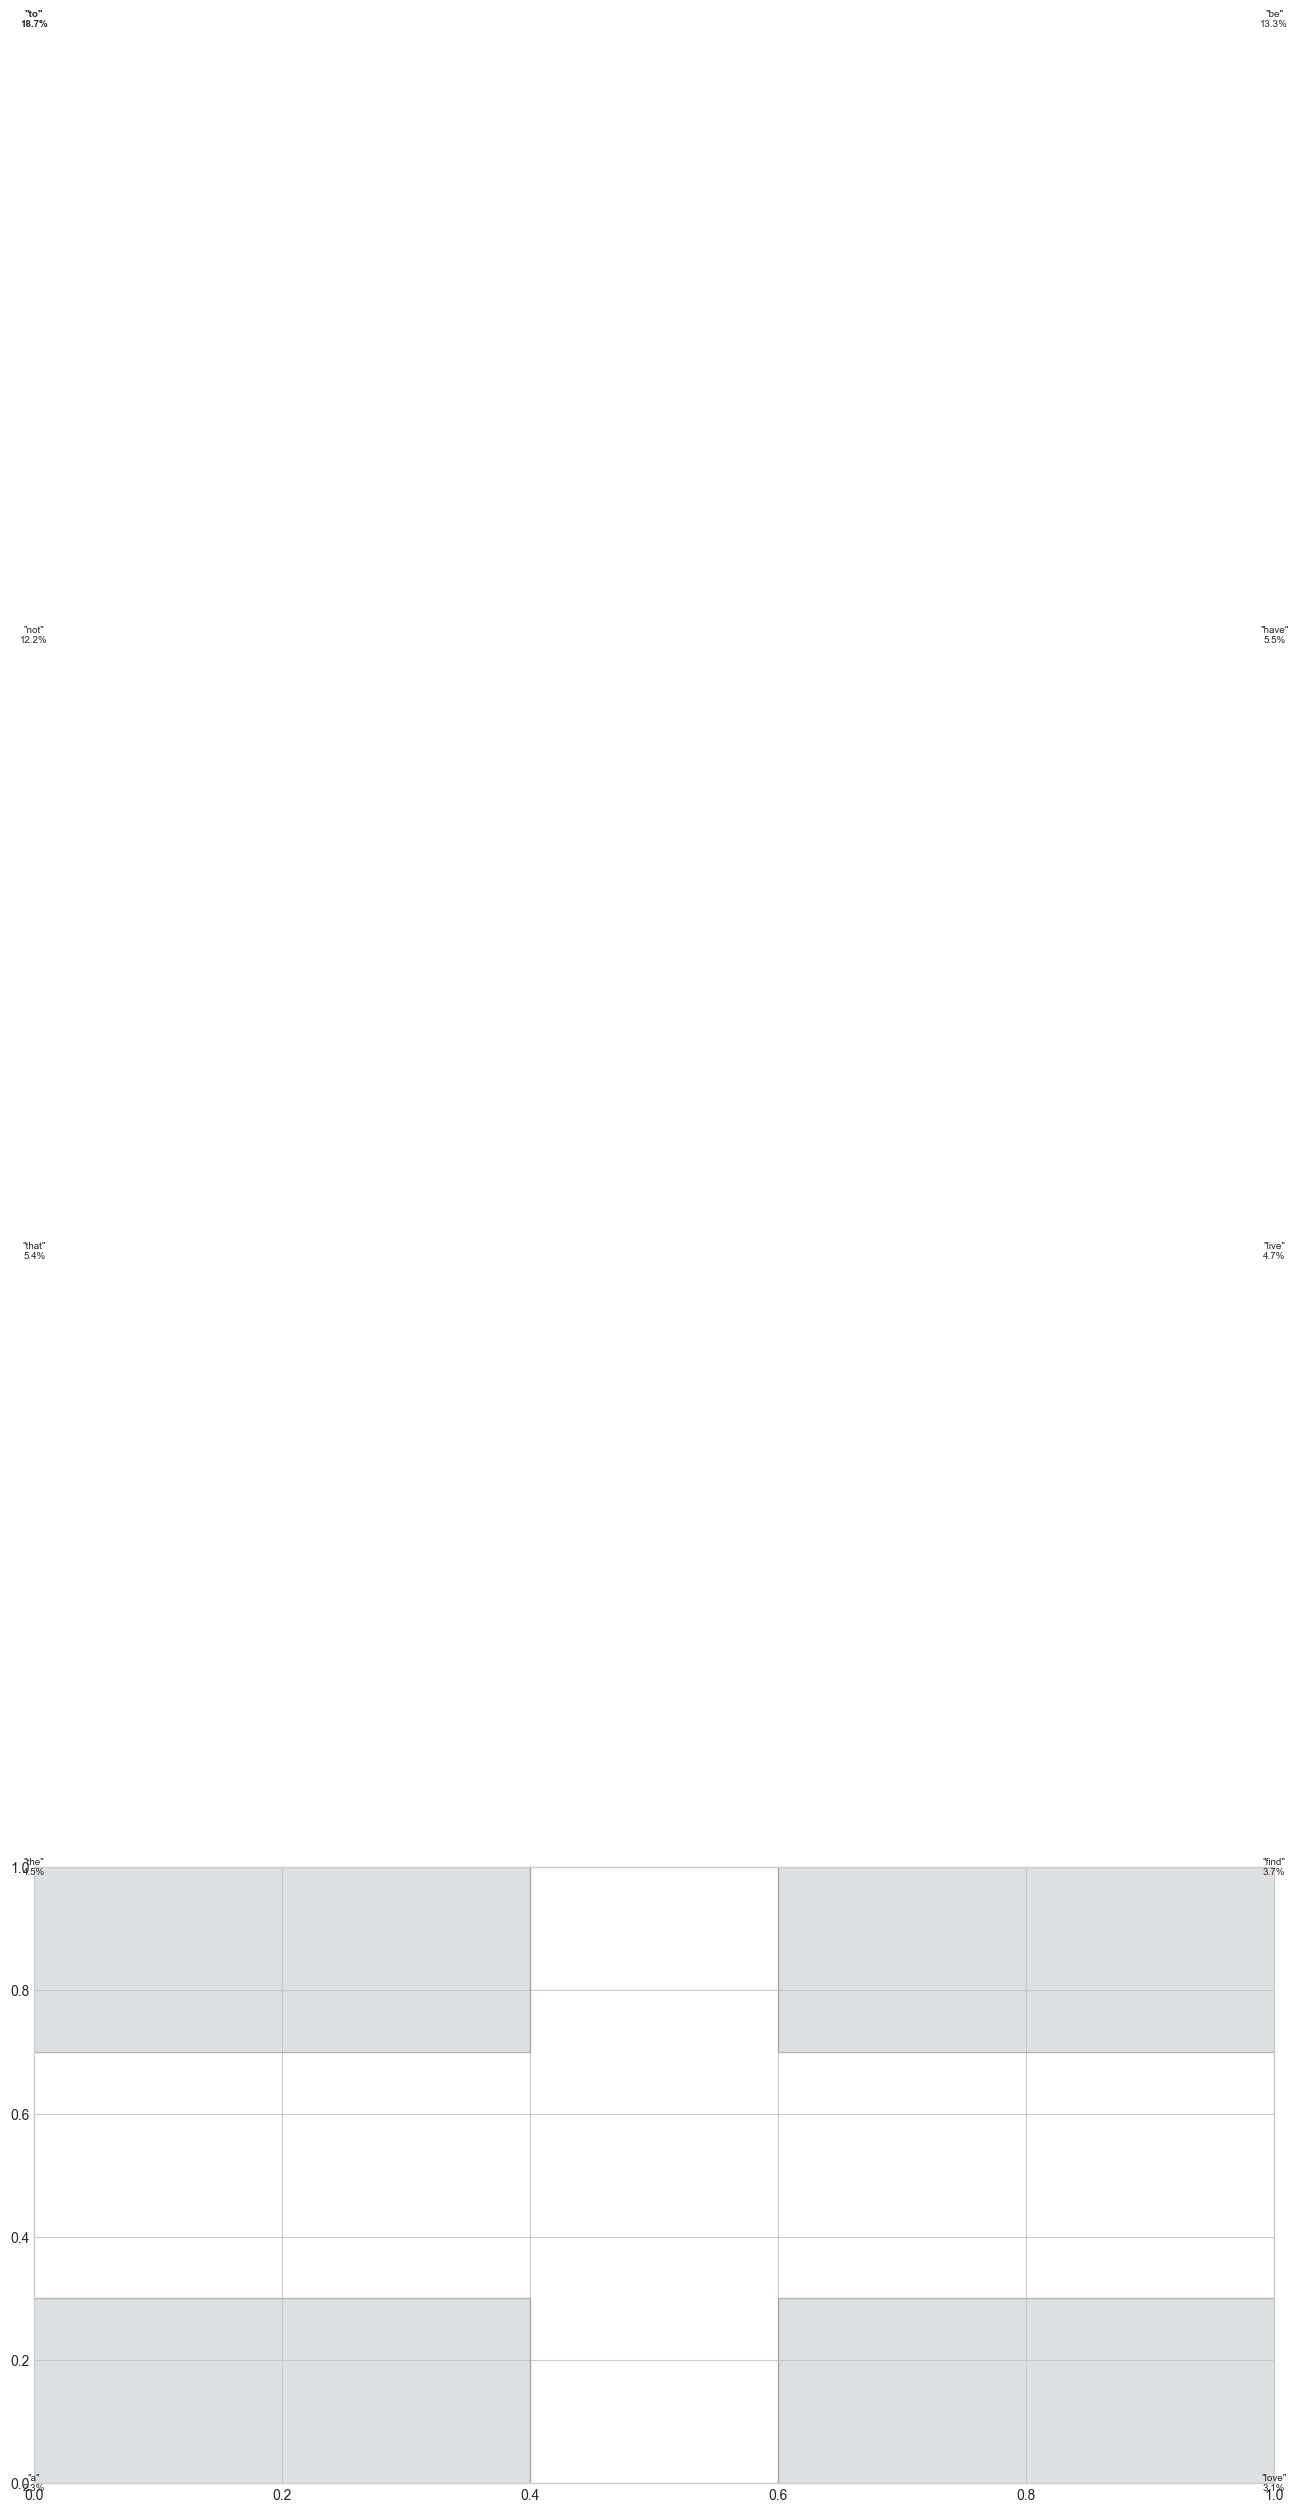

In [4]:
# Visualize the "decision tree" at each step
fig, ax = plt.subplots(figsize=(16, 8))

n_alts = 5  # Show top 5 at each step
n_steps = min(10, len(trace))

for step_idx in range(n_steps):
    t = trace[step_idx]
    alts = t["alternatives"][:n_alts]
    
    for alt_idx, (token, prob) in enumerate(alts):
        token_clean = token.strip()
        is_chosen = (token_clean == t["chosen_token"].strip())
        
        # Position
        x = step_idx
        y = n_alts - 1 - alt_idx
        
        # Color and style
        color = "#2ecc71" if is_chosen else "#bdc3c7"
        fontweight = "bold" if is_chosen else "normal"
        alpha = 1.0 if is_chosen else 0.5
        
        # Draw box
        rect = plt.Rectangle((x - 0.4, y - 0.3), 0.8, 0.6,
                            facecolor=color, alpha=alpha, edgecolor="gray")
        ax.add_patch(rect)
        
        # Label
        label = f'"{ token_clean}"\n{prob:.1%}'
        ax.text(x, y, label, ha="center", va="center", fontsize=7,
               fontweight=fontweight)

    # Draw arrow to next step's chosen token
    if step_idx < n_steps - 1:
        chosen_rank = next(i for i, (tok, _) in enumerate(alts) 
                          if tok.strip() == t["chosen_token"].strip())
        y_from = n_alts - 1 - chosen_rank
        ax.annotate("", xy=(step_idx + 0.6, y_from), xytext=(step_idx + 0.4, y_from),
                    arrowprops=dict(arrowstyle="->", color="#2ecc71", lw=2))

ax.set_xlim(-0.6, n_steps - 0.4)
ax.set_ylim(-0.6, n_alts - 0.4)
ax.set_xticks(range(n_steps))
ax.set_xticklabels([f"Step {i}" for i in range(n_steps)], fontsize=9)
ax.set_yticks(range(n_alts))
ax.set_yticklabels([f"Rank {n_alts - i}" for i in range(n_alts)], fontsize=9)
ax.set_title(f'Generation Decision Tree: "{prompt} ..."', fontsize=13, fontweight="bold")
ax.set_xlabel("Generation Step")
ax.set_ylabel("Token Rank (by probability)")

plt.tight_layout()
plt.show()

## Using the KV Cache: Why Generation Gets Faster

A key optimization: the model doesn't need to recompute attention for **all previous tokens** every time. The **KV (key-value) cache** stores intermediate computations from previous positions so only the new token needs full computation.

HuggingFace Transformers handles this automatically via `past_key_values`:

In [5]:
import time

prompt = "Artificial intelligence will transform"
input_ids = tokenizer.encode(prompt, return_tensors="pt")
n_tokens = 50

# Method 1: No cache (recompute everything each step)
start = time.time()
generated_no_cache = input_ids[0].tolist()
with torch.no_grad():
    for _ in range(n_tokens):
        outputs = model(torch.tensor([generated_no_cache]))
        next_id = outputs.logits[0, -1, :].argmax().item()
        generated_no_cache.append(next_id)
time_no_cache = time.time() - start

# Method 2: With KV cache (only process new token)
start = time.time()
generated_cache = input_ids[0].tolist()
past = None
curr_ids = input_ids
with torch.no_grad():
    for _ in range(n_tokens):
        outputs = model(curr_ids, past_key_values=past, use_cache=True)
        past = outputs.past_key_values
        next_id = outputs.logits[0, -1, :].argmax().item()
        generated_cache.append(next_id)
        curr_ids = torch.tensor([[next_id]])  # Only feed the new token
time_cache = time.time() - start

print(f"Generated {n_tokens} tokens:")
print(f"  Without cache: {time_no_cache:.3f}s")
print(f"  With KV cache: {time_cache:.3f}s")
print(f"  Speedup: {time_no_cache / time_cache:.1f}x")
print(f"\nOutput: {tokenizer.decode(generated_cache)}")

# Verify both methods produce the same output (greedy → deterministic)
assert generated_no_cache == generated_cache, "Outputs differ!"
print("\nBoth methods produce identical output ✓")

Generated 50 tokens:
  Without cache: 1.211s
  With KV cache: 0.382s
  Speedup: 3.2x

Output: Artificial intelligence will transform the way we think about the world. It will change how we think about the world. It will change how we think about the world. It will change how we think about the world. It will change how we think about the world. It will

Both methods produce identical output ✓


## Scoring an Existing Sequence

We can also use the model to **score** text it didn't generate. This is how perplexity is computed: feed the model a sequence and check the probability it assigns to each actual token.

This is the foundation for evaluating how "surprised" a model is by a given text.

In [6]:
def score_sequence(text):
    """Score each token in a sequence — what probability did the model assign?"""
    input_ids = tokenizer.encode(text, return_tensors="pt")
    
    with torch.no_grad():
        outputs = model(input_ids)
        logits = outputs.logits  # [1, seq_len, vocab_size]
    
    # For each position i, logits[0, i] predicts token at position i+1
    # So we compare logits[0, :-1] against actual tokens at positions [1:]
    shift_logits = logits[0, :-1, :]  # [seq_len-1, vocab_size]
    shift_labels = input_ids[0, 1:]    # [seq_len-1]
    
    # Get probability of each actual token
    all_probs = F.softmax(shift_logits, dim=-1)
    token_probs = all_probs.gather(1, shift_labels.unsqueeze(1)).squeeze(1)
    token_logprobs = torch.log(token_probs)
    
    results = []
    for i in range(len(shift_labels)):
        results.append({
            "position": i + 1,
            "token": tokenizer.decode([shift_labels[i]]),
            "token_id": shift_labels[i].item(),
            "prob": token_probs[i].item(),
            "logprob": token_logprobs[i].item(),
        })
    
    return results

# Score two sentences — one natural, one weird
sentences = [
    "The cat sat on the mat and purred contentedly.",
    "The cat sat on the mat and computed logarithms.",
]

for text in sentences:
    results = score_sequence(text)
    
    print(f'"{ text}"\n')
    
    # Color-coded display
    total_logprob = 0
    for r in results:
        total_logprob += r["logprob"]
        # Visual indicator of probability
        if r["prob"] > 0.3:
            indicator = "███"
        elif r["prob"] > 0.05:
            indicator = "██░"
        elif r["prob"] > 0.01:
            indicator = "█░░"
        else:
            indicator = "░░░"
        print(f"  {indicator} {r['token']:>15s}  P={r['prob']:8.4f}  logP={r['logprob']:7.3f}")
    
    avg_logprob = total_logprob / len(results)
    perplexity = np.exp(-avg_logprob)
    print(f"\n  Total log-prob: {total_logprob:.3f}")
    print(f"  Perplexity: {perplexity:.1f} (lower = more expected)")
    print()

"The cat sat on the mat and purred contentedly."

  ░░░             cat  P=  0.0001  logP= -9.196
  ░░░             sat  P=  0.0007  logP= -7.259
  ██░              on  P=  0.2240  logP= -1.496
  ███             the  P=  0.4537  logP= -0.790
  ░░░             mat  P=  0.0040  logP= -5.511
  ██░             and  P=  0.1499  logP= -1.898
  ░░░             pur  P=  0.0002  logP= -8.459
  ███             red  P=  0.6043  logP= -0.504
  ░░░         content  P=  0.0003  logP= -8.157
  ███            edly  P=  0.9901  logP= -0.010
  ███               .  P=  0.4064  logP= -0.901

  Total log-prob: -44.180
  Perplexity: 55.5 (lower = more expected)

"The cat sat on the mat and computed logarithms."

  ░░░             cat  P=  0.0001  logP= -9.196
  ░░░             sat  P=  0.0007  logP= -7.259
  ██░              on  P=  0.2240  logP= -1.496
  ███             the  P=  0.4537  logP= -0.790
  ░░░             mat  P=  0.0040  logP= -5.511
  ██░             and  P=  0.1499  logP= -1.898
  ░░░       

## Key Takeaways

1. **Autoregressive generation** produces text one token at a time, each conditioned on all previous tokens
2. The **sequence probability** is the product of individual token probabilities (sum of log-probs)
3. The **KV cache** avoids recomputing attention for previous tokens, providing significant speedup
4. Models can **score existing text** by measuring the probability assigned to each actual token
5. **Entropy** at each step reveals how uncertain the model is — high entropy means many plausible continuations

**Next up:** Using Ollama to explore practical applications — perplexity, confidence estimation, and uncertainty detection with a capable model.